In [1]:
# import os
# import shutil

# base_path = "/kaggle/input/datasets/mohitsingh1804/plantvillage/PlantVillage"
# # print(base_path)

# merged_path = "/kaggle/working/merged_dataset"
# os.makedirs(merged_path, exist_ok=True)
# # print(merged_path)

# def merge(src_folder):
#     for class_name in os.listdir(src_folder):
#         class_path = os.path.join(src_folder, class_name)

#         if not os.path.isdir(class_path):
#             continue

#         target_class = os.path.join(merged_path, class_name)
#         os.makedirs(target_class, exist_ok=True)

#         for img in os.listdir(class_path):
#             shutil.copy2(
#                 os.path.join(class_path, img),
#                 os.path.join(target_class, img)
#             )

# # merge train + val
# merge(os.path.join(base_path, "train"))
# merge(os.path.join(base_path, "val"))

# print("Merge completed!")

In [1]:
import torch
print("GPU working:",torch.cuda.is_available())
print("GPU name:",torch.cuda.get_device_name(0))

GPU working: True
GPU name: NVIDIA GeForce RTX 3070 Ti


In [2]:
import os
import shutil

# Your actual local paths (use raw string r"" to avoid slash issues)
base_path = r"C:\Users\23301205\Downloads\archive\PlantVillage"
merged_path = r"C:\Users\23301205\Downloads\archive\merged"

# Create merged folder if not exists
os.makedirs(merged_path, exist_ok=True)

print("Base Path:", base_path)
print("Merged Path:", merged_path)

Base Path: C:\Users\23301205\Downloads\archive\PlantVillage
Merged Path: C:\Users\23301205\Downloads\archive\merged


In [3]:
print("Merging is started")
def merge(src_folder):
    for class_name in os.listdir(src_folder):
        class_path = os.path.join(src_folder, class_name)

        # Skip if not a folder
        if not os.path.isdir(class_path):
            continue

        # Create class folder in merged directory
        target_class = os.path.join(merged_path, class_name)
        os.makedirs(target_class, exist_ok=True)

        # Copy all images
        for img in os.listdir(class_path):
            src_file = os.path.join(class_path, img)
            dst_file = os.path.join(target_class, img)

            shutil.copy2(src_file, dst_file)
merge(os.path.join(base_path, "train"))
merge(os.path.join(base_path, "val"))   # change to "val" if needed

print("✅ Merge completed!")

Merging is started
✅ Merge completed!


In [4]:
print("Spliting is started")
import os
import shutil
import random

# ===============================
# Paths (LOCAL WINDOWS)
# ===============================
merged_path = r"C:\Users\23301205\Downloads\archive\merged"
final_path  = r"C:\Users\23301205\Downloads\archive\dataset_final"

# ===============================
# Split ratios
# ===============================
train_ratio = 0.70
val_ratio   = 0.15
test_ratio  = 0.15
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(final_path, split), exist_ok=True)
# Random seed for reproducibility
random.seed(42)

for class_name in os.listdir(merged_path):

    class_path = os.path.join(merged_path, class_name)

    if not os.path.isdir(class_path):
        continue

    images = os.listdir(class_path)
    random.shuffle(images)

    total = len(images)

    train_end = int(total * train_ratio)
    val_end   = int(total * (train_ratio + val_ratio))

    train_files = images[:train_end]
    val_files   = images[train_end:val_end]
    test_files  = images[val_end:]

    # Copy function
    def copy_files(file_list, split_name):
        split_class_dir = os.path.join(final_path, split_name, class_name)
        os.makedirs(split_class_dir, exist_ok=True)

        for file in file_list:
            src = os.path.join(class_path, file)
            dst = os.path.join(split_class_dir, file)
            shutil.copy2(src, dst)

    # Copy images
    copy_files(train_files, "train")
    copy_files(val_files, "val")
    copy_files(test_files, "test")

print("✅ Dataset successfully split into Train / Validation / Test")

Spliting is started
✅ Dataset successfully split into Train / Validation / Test


In [5]:
print(os.listdir(r"C:\Users\23301205\Downloads\archive\dataset_final"))

['test', 'train', 'val']


In [69]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Flatten, Dropout,Conv2D,MaxPooling2D,GlobalAveragePooling2D
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.layers import Input


In [70]:
dataset_path = r"C:\Users\23301205\Downloads\archive\dataset_final"
train_path = dataset_path + "/train"
val_path = dataset_path + "/val"
test_path = dataset_path + "/test"

In [71]:
# Image preprocessing
# img_size = (224,224)
# batch_size = 64
# train_datagen = ImageDataGenerator(
#     rescale=1./255,
#     rotation_range=20,
#     zoom_range=0.2,
#     horizontal_flip=True
# )
# test_val_datagen = ImageDataGenerator(rescale=1./255)
# train_data = train_datagen.flow_from_directory(
#     train_path,
#     target_size=img_size,
#     batch_size=batch_size,
#     class_mode='categorical'
# )
# val_data = test_val_datagen.flow_from_directory(
#     val_path,
#     target_size=img_size,
#     batch_size=batch_size,
#     class_mode='categorical'
# )
# test_data = test_val_datagen.flow_from_directory(
#     test_path,
#     target_size=img_size,
#     batch_size=batch_size,
#     class_mode='categorical',
#     shuffle=False
# )


train_data = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(224,224),
    batch_size=64
)
val_data = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=(224,224),
    batch_size=64
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(224,224),
    batch_size=64,
    shuffle=False
)
num_classes = len(train_data.class_names)
print("Total Classes:",num_classes)
print("Done")

Found 37997 files belonging to 38 classes.
Found 8146 files belonging to 38 classes.
Found 8162 files belonging to 38 classes.
Total Classes: 38
Done


In [72]:
# Adding Normalization and prefetch
train_data = train_data.map(lambda x, y: (x/255.0, y)).prefetch(tf.data.AUTOTUNE)
val_data = val_data.map(lambda x, y: (x/255.0, y)).prefetch(tf.data.AUTOTUNE)
test_data = test_data.map(lambda x, y: (x/255.0, y)).prefetch(tf.data.AUTOTUNE)

In [73]:
# Adding augmentation GPU freiendly
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2)
])

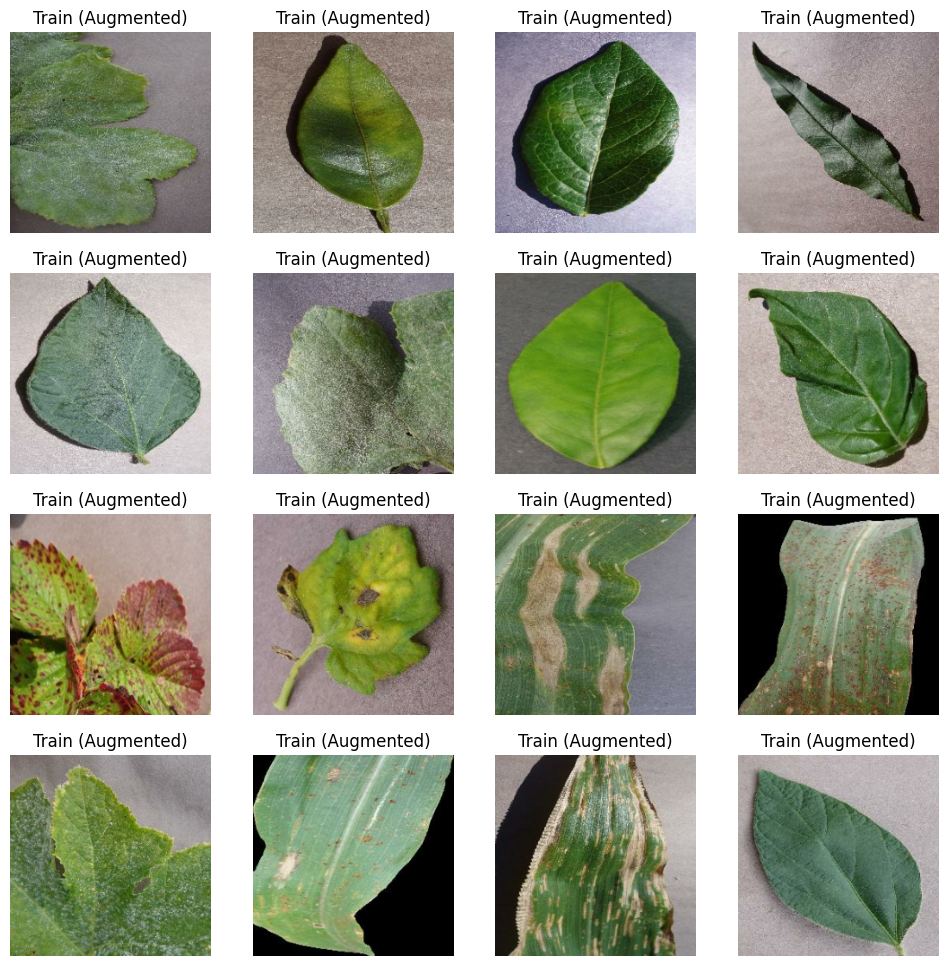

In [74]:
# train data with augmentation
import matplotlib.pyplot as plt
train_iterator = iter(train_data)
images,labels = next(train_iterator)
# images, labels = next(train_data)

plt.figure(figsize=(12,12))

for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(images[i])
    plt.title("Train (Augmented)")
    plt.axis("off")

plt.show()


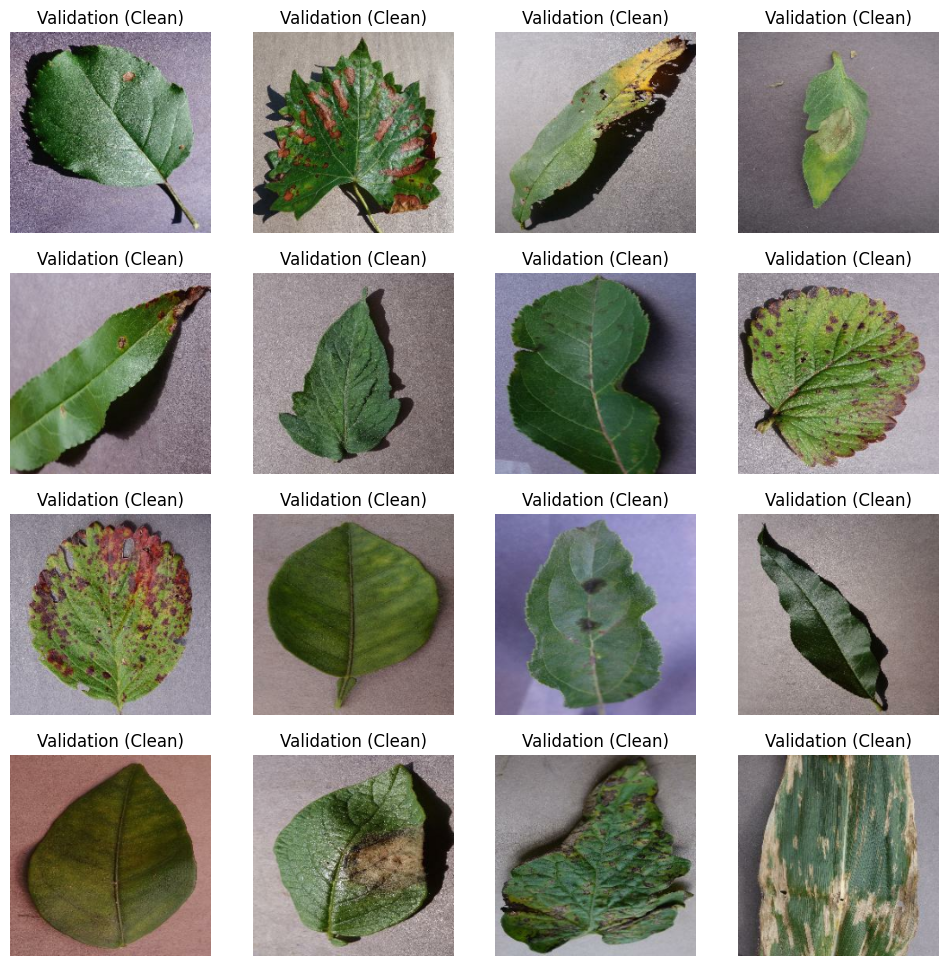

In [75]:
# images, labels = next(val_data)
val_iterator = iter(val_data)
images,labels = next(val_iterator)
plt.figure(figsize=(12,12))

for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(images[i])
    plt.title("Validation (Clean)")
    plt.axis("off")

plt.show()

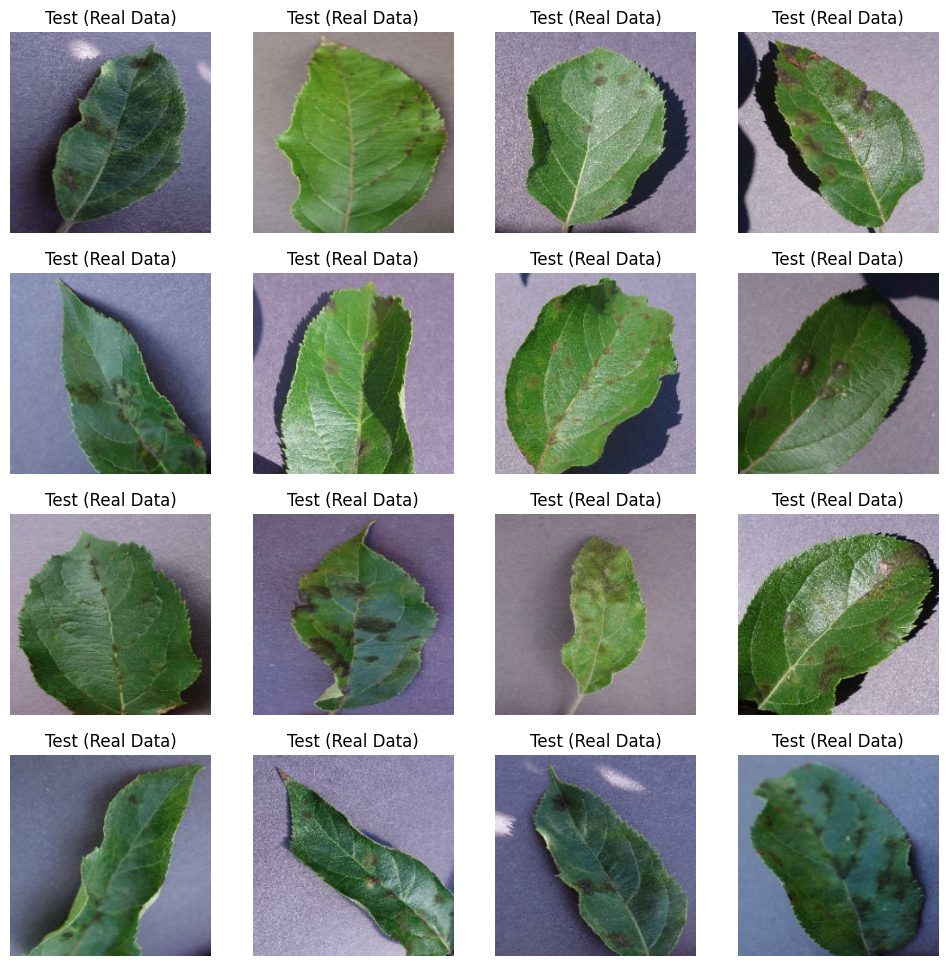

In [76]:
# Test data, final real data
test_iterator = iter(test_data)
images,labels = next(test_iterator)
plt.figure(figsize=(12,12))

for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(images[i])
    plt.title("Test (Real Data)")
    plt.axis("off")

plt.show()

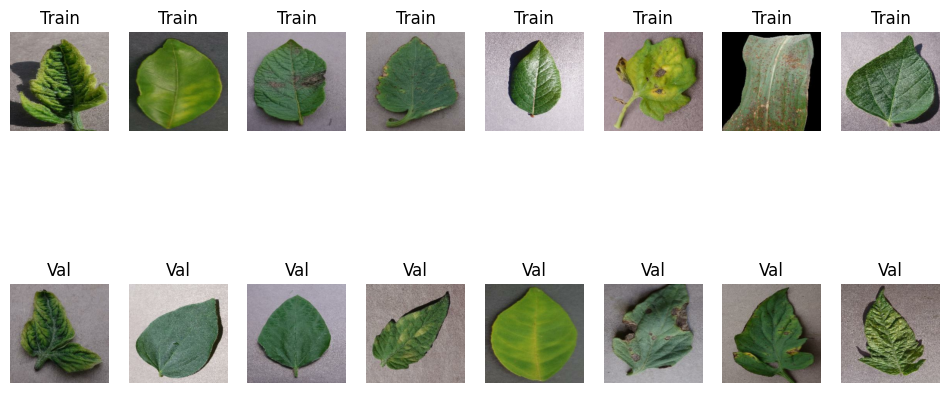

In [77]:
# train vs validation comparison
train_iterator = iter(train_data)
val_iterator = iter(val_data)
train_images, _ = next(train_iterator)
val_images, _ = next(val_iterator)

plt.figure(figsize=(12,6))

for i in range(8):

    # Train (Augmented)
    plt.subplot(2,8,i+1)
    plt.imshow(train_images[i])
    plt.title("Train")
    plt.axis("off")

    # Validation (Clean)
    plt.subplot(2,8,i+9)
    plt.imshow(val_images[i])
    plt.title("Val")
    plt.axis("off")

plt.show()

In [78]:
# CNN model
# cnn_model = Sequential()

# cnn_model.add(Conv2D(32,(3,3),activation='relu',input_shape=(224,224,3)))
# cnn_model.add(MaxPooling2D(2,2))

# cnn_model.add(Conv2D(64,(3,3),activation='relu'))
# cnn_model.add(MaxPooling2D(2,2))

# cnn_model.add(Conv2D(128,(3,3),activation='relu'))
# cnn_model.add(MaxPooling2D(2,2))

# cnn_model.add(Flatten())
# cnn_model.add(Dense(128,activation='relu'))
# cnn_model.add(Dropout(0.5))

# cnn_model.add(Dense(train_data.num_classes,activation='softmax'))

# cnn_model.compile(
#     optimizer='adam',
#     loss='categorical_crossentropy',
#     metrics=['accuracy']
# )
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Dropout, GlobalAveragePooling2D, BatchNormalization, Input

# num_classes = 3  # CHANGE THIS based on your dataset

# cnn_model = Sequential([
#     Input(shape=(224,224,3)),
#     data_augmentation,

#     Conv2D(32,(3,3),activation='relu'),
#     BatchNormalization(),
#     MaxPooling2D(2,2),

#     Conv2D(64,(3,3),activation='relu'),
#     BatchNormalization(),
#     MaxPooling2D(2,2),

#     Conv2D(128,(3,3),activation='relu'),
#     BatchNormalization(),
#     MaxPooling2D(2,2),

#     GlobalAveragePooling2D(),

#     Dense(128,activation='relu'),
#     Dropout(0.5),

#     Dense(num_classes,activation='softmax')
# ])

# print("CNN Initialization done")

In [79]:
# Building model
cnn_model = Sequential([
    Input(shape=(224,224,3)),
    data_augmentation,
    Conv2D(32, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),
    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])
print("hello")

hello


In [80]:
# cnn_model.compile(
#     optimizer='adam',
#     # loss='categorical_crossentropy',
#     loss='sparse_categorical_crossentropy',
#     metrics=['accuracy']
# )
cnn_model.compile(
    optimizer='adam',
    # loss='categorical_crossentropy',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Hello")

Hello


In [81]:
# # Train CNN Model
# print("Model training is started")
# cnn_history = cnn_model.fit(
#     train_data,
#     validation_data=val_data,
#     epochs=10
# )
# print("Model tarining done")
# # =========================
# # 7. Evaluate Model
# # =========================
# test_loss, test_acc = cnn_model.evaluate(test_data)

# print("Test Accuracy:", test_acc)

# # =========================
# # 8. Save Model
# # =========================
# cnn_model.save("cnn_model.h5")
print("Model training is started")
cnn_history = cnn_model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)
print("Model tarining done")
# =========================
# 7. Evaluate Model
# =========================
test_loss, test_acc = cnn_model.evaluate(test_data)

print("Test Accuracy:", test_acc)

# =========================
# 8. Save Model
# =========================
cnn_model.save("cnn_model.h5")
print("Model Training is done")

Model training is started
Epoch 1/10
594/594 ━━━━━━━━━━━━━━━━━━━━ 708s 1s/step - accuracy: 0.5435 - loss: 1.6336 - val_accuracy: 0.3208 - val_loss: 3.2614
Epoch 2/10
594/594 ━━━━━━━━━━━━━━━━━━━━ 695s 1s/step - accuracy: 0.7322 - loss: 0.8931 - val_accuracy: 0.7315 - val_loss: 0.9007
Epoch 3/10
594/594 ━━━━━━━━━━━━━━━━━━━━ 695s 1s/step - accuracy: 0.8023 - loss: 0.6463 - val_accuracy: 0.4008 - val_loss: 5.2910
Epoch 4/10
594/594 ━━━━━━━━━━━━━━━━━━━━ 692s 1s/step - accuracy: 0.8422 - loss: 0.5095 - val_accuracy: 0.7631 - val_loss: 0.7689
Epoch 5/10
594/594 ━━━━━━━━━━━━━━━━━━━━ 691s 1s/step - accuracy: 0.8674 - loss: 0.4258 - val_accuracy: 0.5658 - val_loss: 2.6449
Epoch 6/10
594/594 ━━━━━━━━━━━━━━━━━━━━ 691s 1s/step - accuracy: 0.8856 - loss: 0.3708 - val_accuracy: 0.5741 - val_loss: 2.4204
Epoch 7/10
594/594 ━━━━━━━━━━━━━━━━━━━━ 697s 1s/step - accuracy: 0.8978 - loss: 0.3244 - val_accuracy: 0.6801 - val_loss: 1.3264
Epoch 8/10
594/594 ━━━━━━━━━━━━━━━━━━━━ 693s 1s/step - accuracy: 0.9075

Test Accuracy: 0.8145062327384949
Model Training is done


In [100]:
# CNN results
# CNN results
print("Done")
train_acc = cnn_history.history['accuracy'][-1]  # Last epoch
val_acc   = cnn_history.history['val_accuracy'][-1]  # Last epoch

test_loss, test_acc = cnn_model.evaluate(test_data)

print("CNN Train Accuracy :", train_acc)
print("CNN Validation Accuracy :", val_acc)
print("CNN Test Accuracy :", test_acc)
print("Done")

Done
128/128 ━━━━━━━━━━━━━━━━━━━━ 25s 198ms/step - accuracy: 0.8145 - loss: 0.6611
CNN Train Accuracy : 0.9209937453269958
CNN Validation Accuracy : 0.8078811764717102
CNN Test Accuracy : 0.8145062327384949
Done


In [101]:
# Support vector machine
print("Started")
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import numpy as np

# Collect all images and labels
X_train = []
y_train = []
X_test = []
y_test = []

for images, labels in train_data:
    X_train.extend(images.numpy())
    y_train.extend(labels.numpy())

for images, labels in test_data:
    X_test.extend(images.numpy())
    y_test.extend(labels.numpy())

# Convert to numpy arrays
X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# Reshape: flatten each image (224x224x3 = 150528 features)
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

# Apply PCA to reduce dimensions (otherwise too slow)
from sklearn.decomposition import PCA
pca = PCA(n_components=100)
X_train_pca = pca.fit_transform(X_train_flat)
X_test_pca = pca.transform(X_test_flat)

# Train SVM
svm_model = SVC(kernel='rbf', C=10, random_state=42)
svm_model.fit(X_train_pca, y_train)

# Evaluate
y_pred = svm_model.predict(X_test_pca)
print(f"SVM Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("Done")

Started
SVM Accuracy: 0.8645
Done


Started
Found 37997 files belonging to 38 classes.
Found 8146 files belonging to 38 classes.
Found 8162 files belonging to 38 classes.
Total Classes: 38
Class names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tom

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    1.0s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    4.5s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s



Evaluating Random Forest...


[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:    0.2s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:    0.0s finished



=== RANDOM FOREST RESULTS ===
Training Accuracy: 1.0000
Validation Accuracy: 0.6743
Test Accuracy: 0.6682


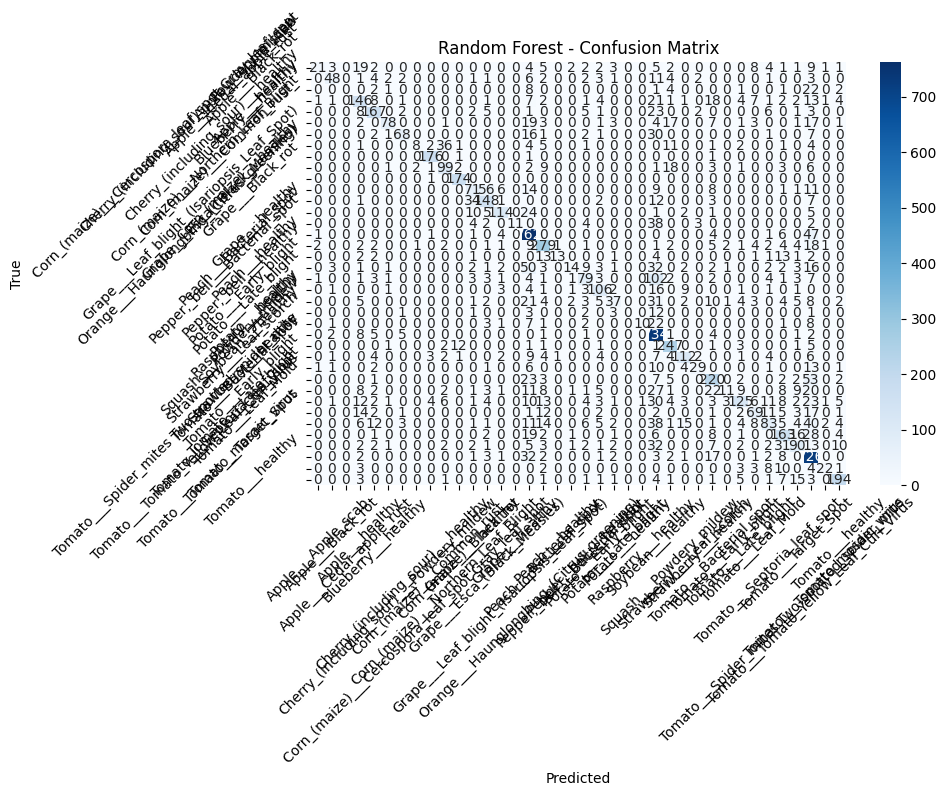


=== CLASSIFICATION REPORT ===


C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.78      0.22      0.34        95
                                 Apple___Black_rot       0.77      0.51      0.62        94
                          Apple___Cedar_apple_rust       0.00      0.00      0.00        42
                                   Apple___healthy       0.59      0.59      0.59       247
                               Blueberry___healthy       0.74      0.74      0.74       226
          Cherry_(including_sour)___Powdery_mildew       0.88      0.49      0.63       158
                 Cherry_(including_sour)___healthy       0.82      0.53      0.64       129
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.73      0.10      0.18        77
                       Corn_(maize)___Common_rust_       0.94      0.98      0.96       179
               Corn_(maize)___Northern_Leaf_Blight       0.65      0.67      0.

In [103]:
print("Started")
import tensorflow as tf
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# ===========================================
# 1. LOAD DATASETS
# ===========================================
train_data = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(224,224),
    batch_size=64,
    label_mode='int'
)

val_data = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=(224,224),
    batch_size=64,
    label_mode='int'
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(224,224),
    batch_size=64,
    shuffle=False,
    label_mode='int'
)

num_classes = len(train_data.class_names)
print("Total Classes:", num_classes)
print("Class names:", train_data.class_names)

# ===========================================
# 2. NORMALIZE DATA
# ===========================================
def normalize(image, label):
    return image / 255.0, label

train_data_norm = train_data.map(normalize).prefetch(tf.data.AUTOTUNE)
val_data_norm = val_data.map(normalize).prefetch(tf.data.AUTOTUNE)
test_data_norm = test_data.map(normalize).prefetch(tf.data.AUTOTUNE)

# ===========================================
# 3. EXTRACT DATA FOR RANDOM FOREST
# ===========================================
print("\nExtracting training data...")
X_train, y_train = [], []
for images, labels in train_data_norm:
    X_train.extend(images.numpy())
    y_train.extend(labels.numpy())

print("Extracting validation data...")
X_val, y_val = [], []
for images, labels in val_data_norm:
    X_val.extend(images.numpy())
    y_val.extend(labels.numpy())

print("Extracting test data...")
X_test, y_test = [], []
for images, labels in test_data_norm:
    X_test.extend(images.numpy())
    y_test.extend(labels.numpy())

# Convert to numpy arrays
X_train = np.array(X_train)
y_train = np.array(y_train)
X_val = np.array(X_val)
y_val = np.array(y_val)
X_test = np.array(X_test)
y_test = np.array(y_test)

print(f"\nData shapes:")
print(f"Training: {X_train.shape}")
print(f"Validation: {X_val.shape}")
print(f"Test: {X_test.shape}")

# ===========================================
# 4. FLATTEN IMAGES
# ===========================================
print("\nFlattening images...")
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print(f"Features per image: {X_train_flat.shape[1]}")

# ===========================================
# 5. APPLY PCA (to reduce dimensions)
# ===========================================
print("\nApplying PCA to reduce dimensions...")
n_components = min(100, X_train_flat.shape[1])
pca = PCA(n_components=n_components, random_state=42)
X_train_pca = pca.fit_transform(X_train_flat)
X_val_pca = pca.transform(X_val_flat)
X_test_pca = pca.transform(X_test_flat)

print(f"Reduced from {X_train_flat.shape[1]} to {X_train_pca.shape[1]} features")
print(f"Explained variance: {sum(pca.explained_variance_ratio_):.2%}")

# ===========================================
# 6. TRAIN RANDOM FOREST
# ===========================================
print("\n" + "="*50)
print("TRAINING RANDOM FOREST")
print("="*50)

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_model.fit(X_train_pca, y_train)

# ===========================================
# 7. EVALUATE RANDOM FOREST
# ===========================================
print("\nEvaluating Random Forest...")

# Predictions
y_train_pred = rf_model.predict(X_train_pca)
y_val_pred = rf_model.predict(X_val_pca)
y_test_pred = rf_model.predict(X_test_pca)

# Accuracies
train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_val, y_val_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("\n=== RANDOM FOREST RESULTS ===")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

# ===========================================
# 8. CONFUSION MATRIX
# ===========================================
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=train_data.class_names,
            yticklabels=train_data.class_names)
plt.title('Random Forest - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.tight_layout()
plt.show()

# ===========================================
# 9. CLASSIFICATION REPORT
# ===========================================
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_test_pred, 
                          target_names=train_data.class_names))

# ===========================================
# 10. FEATURE IMPORTANCE (Optional)
# ===========================================
print("\nTop 10 Most Important Features:")
feature_importance = rf_model.feature_importances_
top_10_idx = np.argsort(feature_importance)[-10:][::-1]
for i, idx in enumerate(top_10_idx, 1):
    print(f"{i}. Feature {idx}: {feature_importance[idx]:.6f}")

# ===========================================
# 11. SAVE MODEL (Optional)
# ===========================================
import joblib
joblib.dump(rf_model, 'random_forest_model.pkl')
print("\nModel saved as 'random_forest_model.pkl'")

print("\nRandom Forest training completed successfully!")
print("Done")

In [105]:
print("Started")
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Train AdaBoost
print("Training AdaBoost...")
adaboost_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

adaboost_model.fit(X_train_pca, y_train)

# Predictions
y_train_pred = adaboost_model.predict(X_train_pca)
y_val_pred = adaboost_model.predict(X_val_pca)
y_test_pred = adaboost_model.predict(X_test_pca)

# Calculate accuracies
train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_val, y_val_pred)
test_acc = accuracy_score(y_test, y_test_pred)

# Print results
print("\n=== ADABOOST RESULTS ===")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print("Done")

Started
Training AdaBoost...

=== ADABOOST RESULTS ===
Training Accuracy: 0.2431
Validation Accuracy: 0.2431
Test Accuracy: 0.2411
Done


In [106]:
print("Started")
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Train KNN
print("Training KNN...")
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

knn_model.fit(X_train_pca, y_train)

# Predictions
y_train_pred = knn_model.predict(X_train_pca)
y_val_pred = knn_model.predict(X_val_pca)
y_test_pred = knn_model.predict(X_test_pca)

# Calculate accuracies
train_acc = accuracy_score(y_train, y_train_pred)
val_acc = accuracy_score(y_val, y_val_pred)
test_acc = accuracy_score(y_test, y_test_pred)

# Print results
print("\n=== KNN RESULTS ===")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print("Done")

Started
Training KNN...

=== KNN RESULTS ===
Training Accuracy: 0.7814
Validation Accuracy: 0.6786
Test Accuracy: 0.6752
Done


In [111]:
# ResNet50 Model from here
print("Started")
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Started


In [112]:
# # Load and prepare data
# print("started")
# train_data = tf.keras.utils.image_dataset_from_directory(
#     train_path, image_size=(224,224), batch_size=32, label_mode='int'
# )
# val_data = tf.keras.utils.image_dataset_from_directory(
#     val_path, image_size=(224,224), batch_size=32, label_mode='int'
# )
# test_data = tf.keras.utils.image_dataset_from_directory(
#     test_path, image_size=(224,224), batch_size=32, shuffle=False, label_mode='int'
# )

# num_classes = len(train_data.class_names)
# print("Done")

In [113]:
# # Preprocess for ResNet50
# def preprocess(image, label):
#     image = tf.keras.applications.resnet50.preprocess_input(tf.cast(image, tf.float32))
#     return image, label

# train_data = train_data.map(preprocess).prefetch(tf.data.AUTOTUNE)
# val_data = val_data.map(preprocess).prefetch(tf.data.AUTOTUNE)
# test_data = test_data.map(preprocess).prefetch(tf.data.AUTOTUNE)

In [114]:
# Building ResNet50 model from here
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224,224,3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
output = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(optimizer=Adam(0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [115]:
# Training the model
print("Started")
print("Training ResNet50...")
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    verbose=1
)
print("Model Training is done")

Started
Training ResNet50...
Epoch 1/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 746s 626ms/step - accuracy: 0.8557 - loss: 0.4943 - val_accuracy: 0.9607 - val_loss: 0.1205
Epoch 2/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 733s 617ms/step - accuracy: 0.9337 - loss: 0.2018 - val_accuracy: 0.9723 - val_loss: 0.0897
Epoch 3/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 736s 619ms/step - accuracy: 0.9467 - loss: 0.1588 - val_accuracy: 0.9750 - val_loss: 0.0770
Epoch 4/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 736s 619ms/step - accuracy: 0.9516 - loss: 0.1447 - val_accuracy: 0.9779 - val_loss: 0.0675
Epoch 5/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 737s 621ms/step - accuracy: 0.9574 - loss: 0.1241 - val_accuracy: 0.9740 - val_loss: 0.0794
Epoch 6/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 737s 620ms/step - accuracy: 0.9608 - loss: 0.1168 - val_accuracy: 0.9790 - val_loss: 0.0660
Epoch 7/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 737s 621ms/step - accuracy: 0.9632 - loss: 0.1071 - val_accuracy: 0.9816 - val_loss: 0.0564
Epoch 8/10
1188/1188 ━━━━━━━━━━━━

In [116]:
# ===========================================
# 4. EVALUATE - Train, Validation, Test
# ===========================================
print("Started")
train_loss, train_acc = model.evaluate(train_data, verbose=0)
val_loss, val_acc = model.evaluate(val_data, verbose=0)
test_loss, test_acc = model.evaluate(test_data, verbose=0)

print("\n" + "="*50)
print("RESNET50 RESULTS")
print("="*50)
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"\nTraining Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Test Loss: {test_loss:.4f}")
print("Done")

Started

RESNET50 RESULTS
Training Accuracy: 0.9926
Validation Accuracy: 0.9788
Test Accuracy: 0.9822

Training Loss: 0.0212
Validation Loss: 0.0667
Test Loss: 0.0605
Done


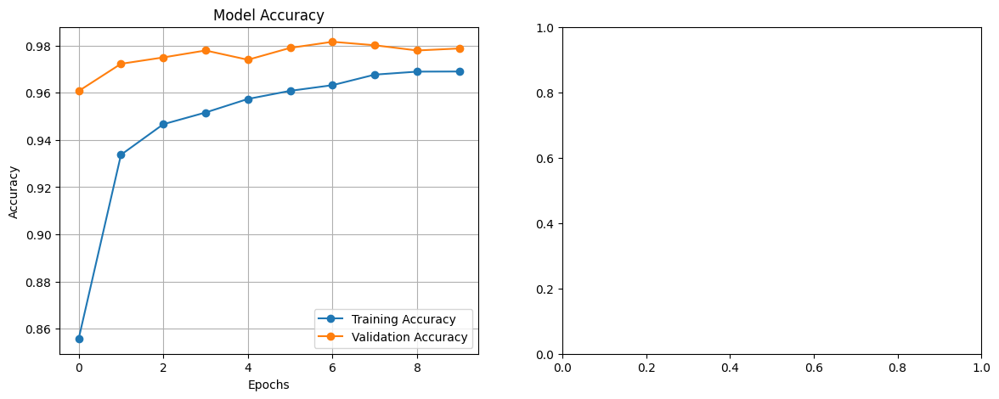

In [117]:
# ===========================================
# 5. PLOT TRAINING HISTORY
# ===========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
axes[0].plot(history.history['accuracy'], label='Training Accuracy', marker='o')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

In [124]:
# # Loss plot
# axes[1].plot(history.history['loss'], label='Training Loss', marker='o')
# axes[1].plot(history.history['val_loss'], label='Validation Loss', marker='o')
# axes[1].set_title('Model Loss')
# axes[1].set_xlabel('Epochs')
# axes[1].set_ylabel('Loss')
# axes[1].legend()
# axes[1].grid(True)

# plt.tight_layout()
# plt.show()
# print("Done")

In [125]:
# # ===========================================
# # 6. PREDICTIONS AND METRICS
# # ===========================================
# # Get predictions
# print("Started")
# y_true = []
# y_pred = []

# for images, labels in test_data:
#     predictions = model.predict(images, verbose=0)
#     y_true.extend(labels.numpy())
#     y_pred.extend(np.argmax(predictions, axis=1))

# y_true = np.array(y_true)
# y_pred = np.array(y_pred)
# print("Done")

In [126]:
# # Classification Report
# print("\n" + "="*50)
# print("CLASSIFICATION REPORT")
# print("="*50)
# print(classification_report(y_true, y_pred, target_names=train_data.class_names))


In [127]:
# # Confusion Matrix
# plt.figure(figsize=(12, 10))
# cm = confusion_matrix(y_true, y_pred)
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
#             xticklabels=train_data.class_names,
#             yticklabels=train_data.class_names)
# plt.title('ResNet50 - Confusion Matrix')
# plt.xlabel('Predicted')
# plt.ylabel('True')
# plt.xticks(rotation=45)
# plt.yticks(rotation=45)
# plt.tight_layout()
# plt.show()


In [128]:
# # Load dataset
# train_data = tf.keras.utils.image_dataset_from_directory(
#     train_dir,
#     image_size=(224,224),
#     batch_size=32
# )

# # Save class names BEFORE prefetch
# class_names = train_data.class_names

# # Then prefetch
# train_data = train_data.prefetch(tf.data.AUTOTUNE)

In [152]:
# Anika's Part from here
print("Started")
train_data = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(224,224),
    batch_size=64
)

val_data = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=(224,224),
    batch_size=64
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(224,224),
    batch_size=64,
    shuffle=False
)
print("Done")

Started
Found 37997 files belonging to 38 classes.
Found 8146 files belonging to 38 classes.
Found 8162 files belonging to 38 classes.
Done


In [153]:
class_names = train_data.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Total Classes:", num_classes)

Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___

In [154]:
print("started")
train_data = train_data.map(lambda x, y: (x/255.0, y)).prefetch(tf.data.AUTOTUNE)
val_data = val_data.map(lambda x, y: (x/255.0, y)).prefetch(tf.data.AUTOTUNE)
test_data = test_data.map(lambda x, y: (x/255.0, y)).prefetch(tf.data.AUTOTUNE)
print("Done")

started
Done


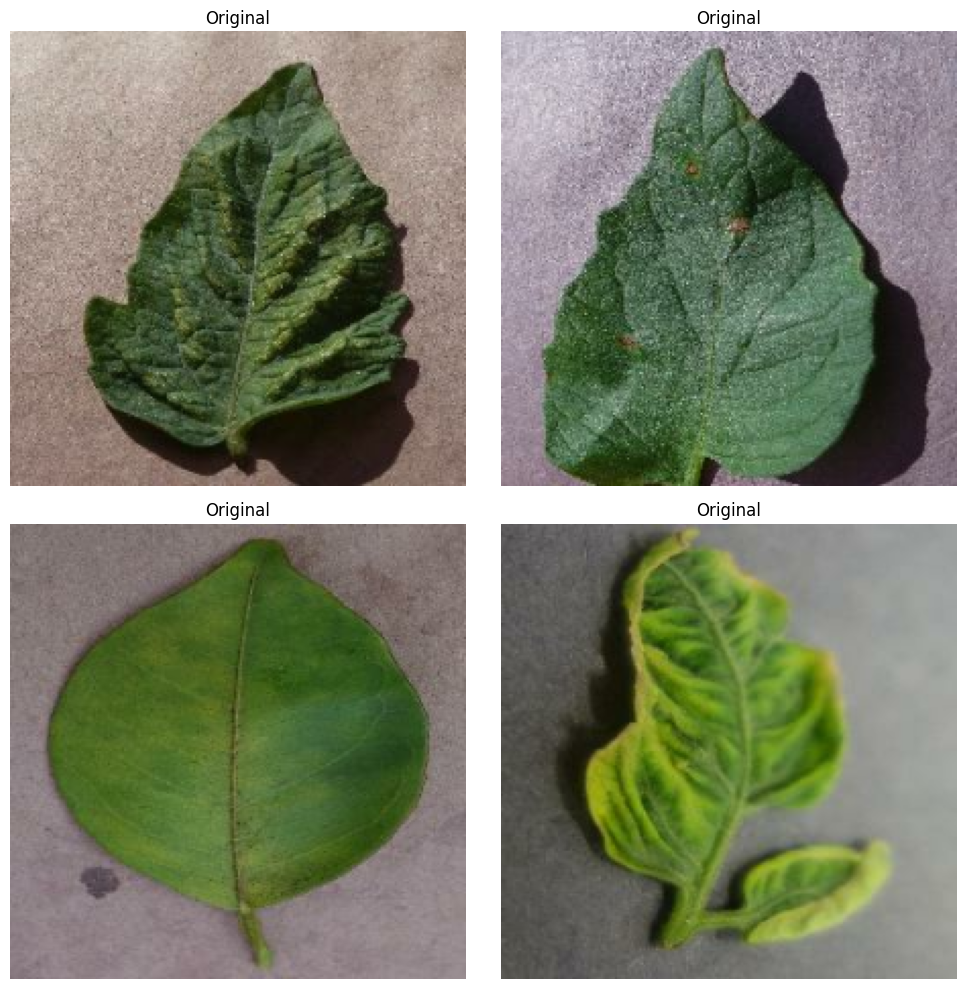

In [155]:
# Original Images
import matplotlib.pyplot as plt

images, labels = next(iter(train_data))

plt.figure(figsize=(10,10))

for i in range(4):
    plt.subplot(2,2,i+1)

    img = images[i].numpy()

    plt.imshow(img)
    plt.title("Original")
    plt.axis("off")

plt.tight_layout()
plt.show()

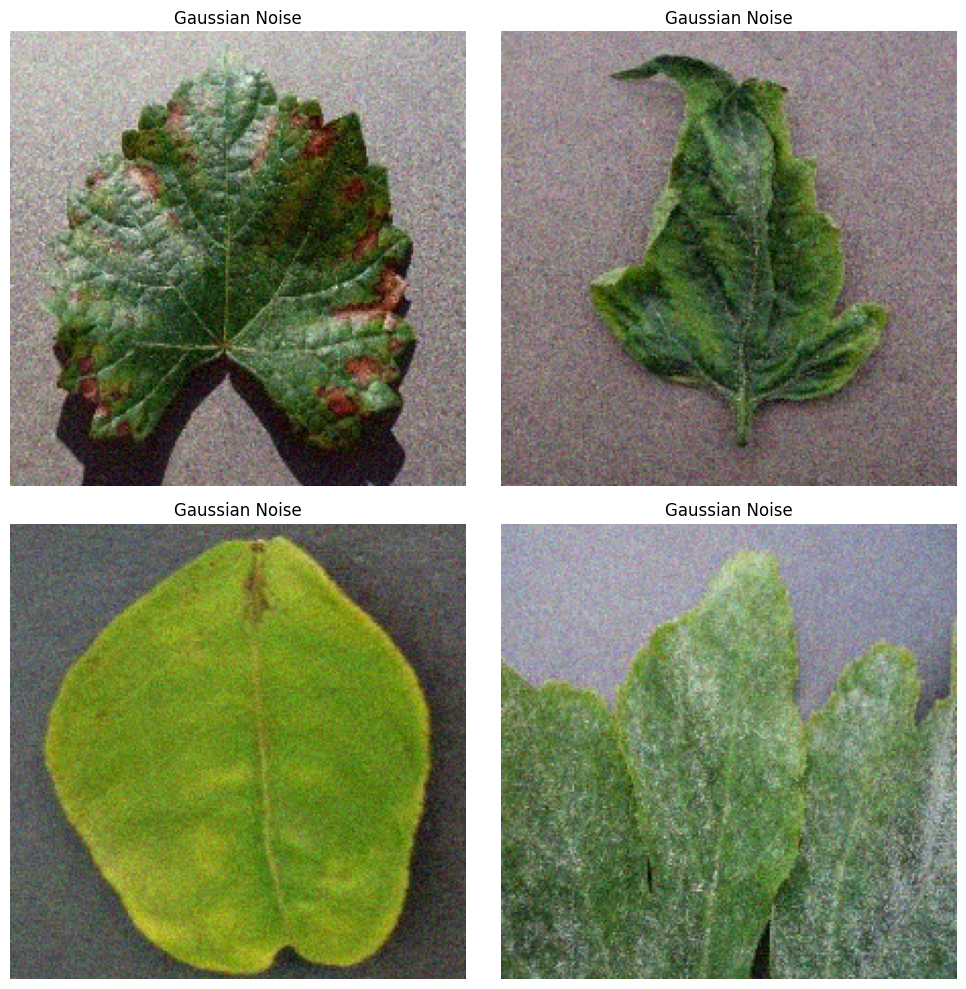

In [156]:
# Gaussian Noise
import matplotlib.pyplot as plt

images, labels = next(iter(train_data))

plt.figure(figsize=(10,10))

for i in range(4):
    plt.subplot(2,2,i+1)

    img = images[i].numpy()

    noisy_img = add_gaussian_noise(img)

    plt.imshow(noisy_img)
    plt.title("Gaussian Noise")
    plt.axis("off")

plt.tight_layout()
plt.show()


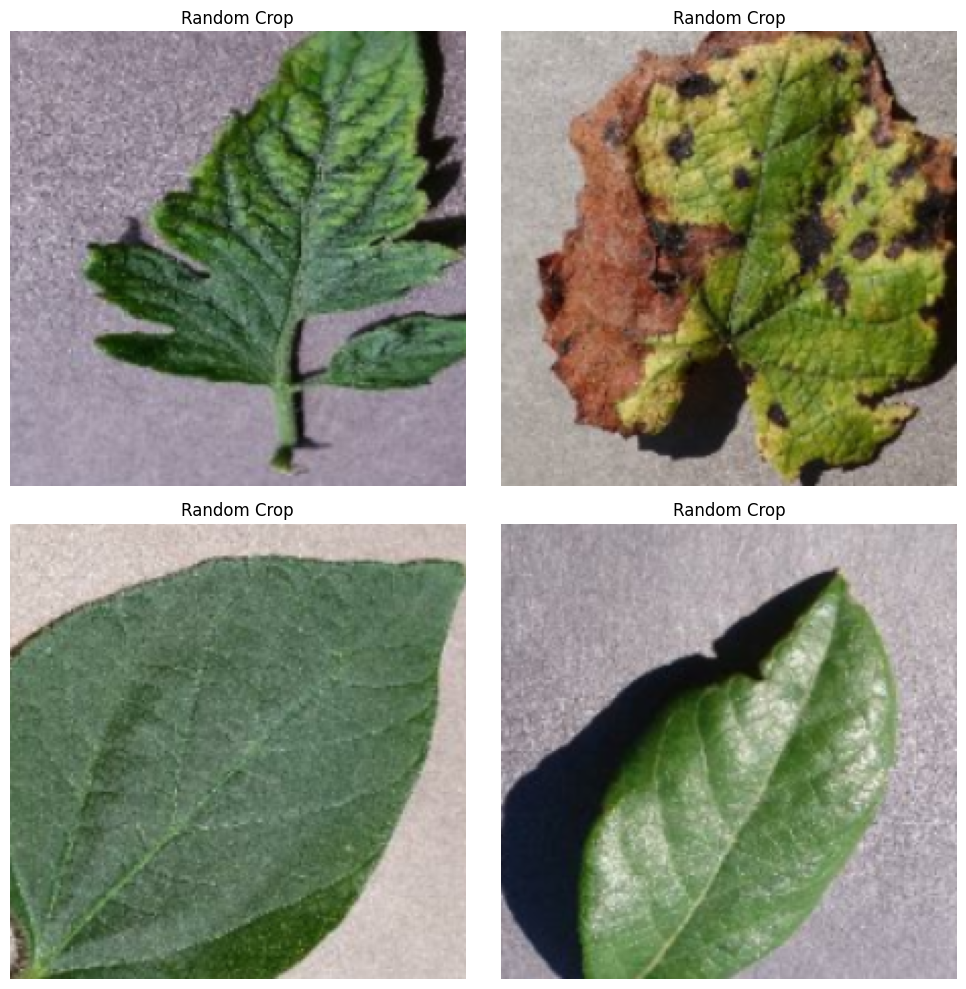

In [157]:
# Random crop
import matplotlib.pyplot as plt

images, labels = next(iter(train_data))

plt.figure(figsize=(10,10))

for i in range(4):
    plt.subplot(2,2,i+1)

    img = images[i].numpy()

    cropped_img = random_crop(img)

    plt.imshow(cropped_img)
    plt.title("Random Crop")
    plt.axis("off")

plt.tight_layout()
plt.show()

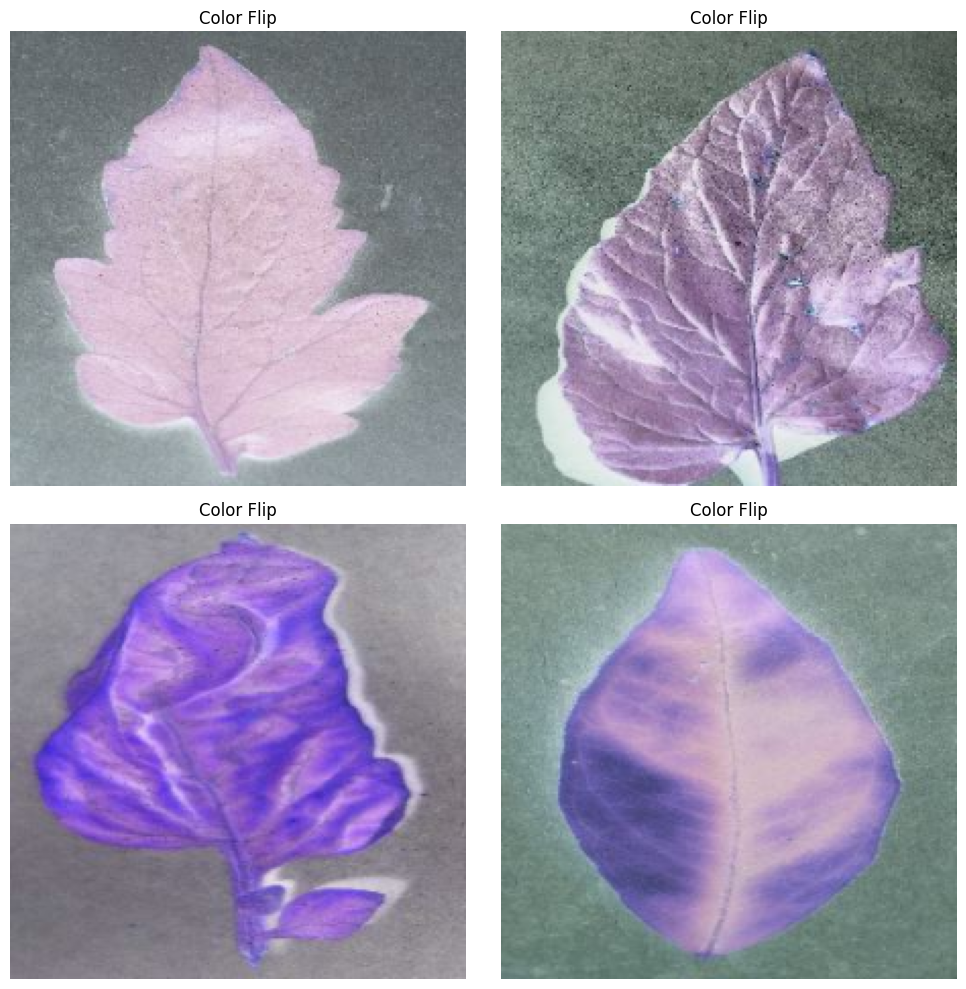

In [158]:
# Color flip
import matplotlib.pyplot as plt

images, labels = next(iter(train_data))

plt.figure(figsize=(10,10))

for i in range(4):
    plt.subplot(2,2,i+1)

    img = images[i].numpy()

    flipped_img = color_flip(img)

    plt.imshow(flipped_img)
    plt.title("Color Flip")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [195]:
print("CNN model starts from here")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np

CNN model starts from here


In [196]:
from sklearn.metrics import classification_report, accuracy_score

print(classification_report(y_true, y_pred))
print("Accuracy:", accuracy_score(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.62      0.75        95
           1       0.94      0.63      0.75        94
           2       1.00      0.88      0.94        42
           3       0.95      0.83      0.89       247
           4       0.97      0.61      0.75       226
           5       0.81      0.95      0.87       158
           6       0.88      0.29      0.44       129
           7       0.70      0.90      0.79        77
           8       1.00      0.99      1.00       179
           9       0.94      0.74      0.83       148
          10       0.96      0.92      0.94       175
          11       0.95      0.79      0.86       177
          12       0.95      0.92      0.93       208
          13       0.55      0.98      0.71       162
          14       0.80      0.55      0.65        64
          15       1.00      0.86      0.92       827
          16       0.99      0.68      0.81       345
          17       0.00    

C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

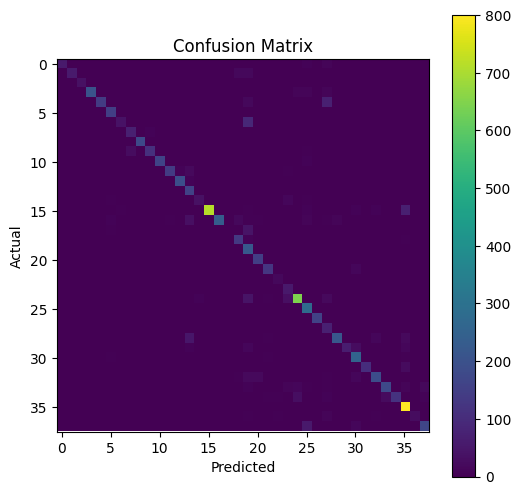

In [197]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,6))
plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.colorbar()
plt.show()

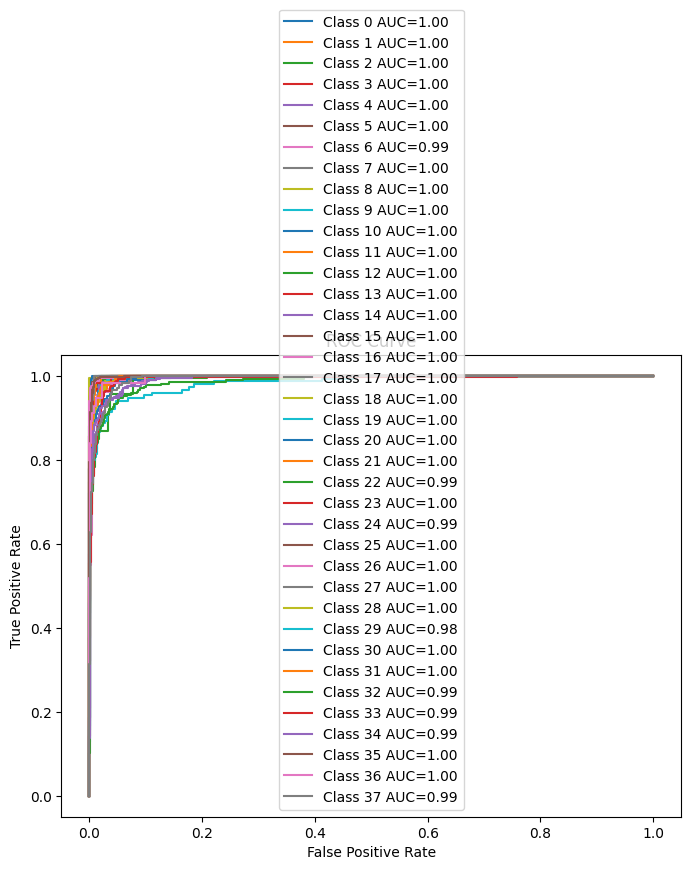

In [198]:
# ROC curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# Convert labels
y_true_bin = label_binarize(y_true, classes=np.arange(num_classes))

plt.figure(figsize=(8,6))

for i in range(num_classes):

    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])

    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"Class {i} AUC={roc_auc:.2f}")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


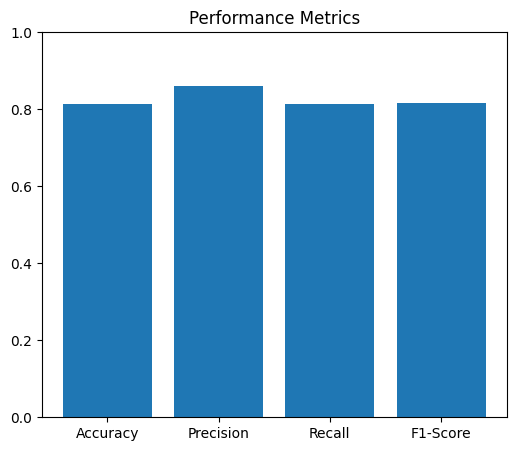

In [199]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
values = [accuracy, precision, recall, f1]

plt.figure(figsize=(6,5))

plt.bar(metrics, values)

plt.ylim(0, 1)

plt.title("Performance Metrics")

plt.show()

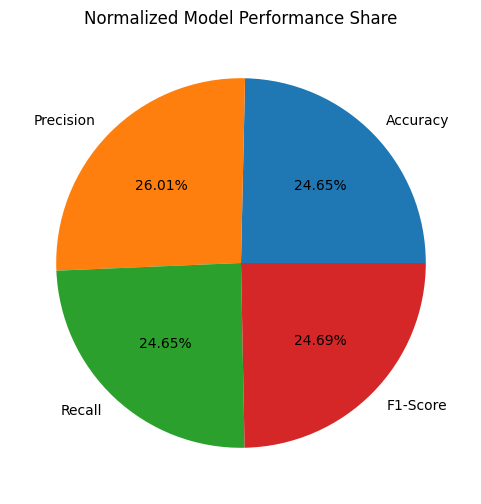

In [200]:
total = sum(values)
normalized = [v/total for v in values]

plt.figure(figsize=(6,6))
plt.pie(normalized, labels=labels, autopct='%1.2f%%')
plt.title("Normalized Model Performance Share")
plt.show()

In [12]:
print("starting")
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Conv2D, MaxPooling2D, Flatten
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import os
print("Done")

starting
Done


In [13]:
# Define paths
print("starting")
train_path = r"C:\Users\23301205\Downloads\archive\dataset_final\train"
test_path = r"C:\Users\23301205\Downloads\archive\dataset_final\test"
val_path = r"C:\Users\23301205\Downloads\archive\dataset_final\val"
print("Done")

starting
Done


In [14]:
# Get class names
print("started")
class_names = sorted(os.listdir(train_path))
num_classes = len(class_names)
print(f"Number of classes: {num_classes}")
print("done")

started
Number of classes: 38
done


In [15]:
print("Staring")
# PART 1: PREPARE DATA FOR SKLEARN MODELS
# ============================================

IMG_SIZE_SKLEARN = (64, 64)

def flatten_data(data_path):
    dataset = tf.keras.utils.image_dataset_from_directory(
        data_path, image_size=IMG_SIZE_SKLEARN, batch_size=32, 
        shuffle=False, label_mode='int'
    )
    images, labels = [], []
    for img_batch, lbl_batch in dataset:
        images.extend(img_batch.numpy())
        labels.extend(lbl_batch.numpy())
    images = np.array(images) / 255.0
    return images.reshape(len(images), -1), np.array(labels)

print("\nLoading data for sklearn models...")
X_train_sk, y_train_sk = flatten_data(train_path)
X_test_sk, y_test_sk = flatten_data(test_path)
print(f"Train shape: {X_train_sk.shape}, Test shape: {X_test_sk.shape}")
print("Done")

Staring

Loading data for sklearn models...
Found 37997 files belonging to 38 classes.
Found 8162 files belonging to 38 classes.
Train shape: (37997, 12288), Test shape: (8162, 12288)
Done


In [17]:
# Train sklearn models
print("start")
sklearn_models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
}
results = {}
conf_matrices = {}

print("\n" + "="*60)
print("SKLEARN MODELS PERFORMANCE")
print("="*60)
print("Done")

start

SKLEARN MODELS PERFORMANCE
Done


In [18]:
print("start")
for name, model in sklearn_models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train_sk, y_train_sk)
    y_pred = model.predict(X_test_sk)
    
    results[name] = {
        'Accuracy': accuracy_score(y_test_sk, y_pred),
        'Precision': precision_score(y_test_sk, y_pred, average='weighted'),
        'Recall': recall_score(y_test_sk, y_pred, average='weighted'),
        'F1-Score': f1_score(y_test_sk, y_pred, average='weighted')
    }
    conf_matrices[name] = confusion_matrix(y_test_sk, y_pred)
    
    print(f"  Accuracy: {results[name]['Accuracy']:.4f}")
    print(f"  Precision: {results[name]['Precision']:.4f}")
    print(f"  Recall: {results[name]['Recall']:.4f}")
    print(f"  F1-Score: {results[name]['F1-Score']:.4f}")
print("Done")

start

Training Random Forest...


C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


  Accuracy: 0.6686
  Precision: 0.6571
  Recall: 0.6686
  F1-Score: 0.6345

Training AdaBoost...


C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


  Accuracy: 0.2555
  Precision: 0.2001
  Recall: 0.2555
  F1-Score: 0.1933

Training KNN...
  Accuracy: 0.5403
  Precision: 0.6241
  Recall: 0.5403
  F1-Score: 0.5163
Done


In [19]:
print("Start")
print("\n" + "="*60)
print("CNN PERFORMANCE")
print("="*60)

# Prepare data for CNN
train_ds_cnn = tf.keras.preprocessing.image_dataset_from_directory(
    train_path, image_size=(128,128), batch_size=32, label_mode='categorical'
).map(lambda x,y: (x/255.0, y))

test_ds_cnn = tf.keras.preprocessing.image_dataset_from_directory(
    test_path, image_size=(128,128), batch_size=32, label_mode='categorical', shuffle=False
).map(lambda x,y: (x/255.0, y))
print("Done")

Start

CNN PERFORMANCE
Found 37997 files belonging to 38 classes.
Found 8162 files belonging to 38 classes.
Done


In [20]:
print("Start")
cnn_model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
print("Done")

Start
Done


C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Started
Loading data for sklearn models...
Found 37997 files belonging to 38 classes.
Found 8162 files belonging to 38 classes.
Done


In [22]:
print("start")
cnn_model.fit(train_ds_cnn, validation_data=test_ds_cnn, epochs=10, verbose=1)

# Evaluate
y_pred_cnn = np.argmax(cnn_model.predict(test_ds_cnn), axis=1)
y_true_cnn = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds_cnn])
print("done")

start
Epoch 1/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 94s 78ms/step - accuracy: 0.5189 - loss: 1.7472 - val_accuracy: 0.7710 - val_loss: 0.7523
Epoch 2/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 93s 78ms/step - accuracy: 0.6996 - loss: 0.9844 - val_accuracy: 0.8386 - val_loss: 0.5296
Epoch 3/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 91s 76ms/step - accuracy: 0.7619 - loss: 0.7549 - val_accuracy: 0.8742 - val_loss: 0.3969
Epoch 4/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 91s 76ms/step - accuracy: 0.8012 - loss: 0.6190 - val_accuracy: 0.8766 - val_loss: 0.3943
Epoch 5/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 91s 76ms/step - accuracy: 0.8274 - loss: 0.5249 - val_accuracy: 0.8688 - val_loss: 0.4123
Epoch 6/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 91s 76ms/step - accuracy: 0.8522 - loss: 0.4459 - val_accuracy: 0.8934 - val_loss: 0.3279
Epoch 7/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 91s 76ms/step - accuracy: 0.8714 - loss: 0.3847 - val_accuracy: 0.8979 - val_loss: 0.3263
Epoch 8/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 91s 77ms/step - accuracy: 0.

In [23]:
print("Start")
results['CNN'] = {
    'Accuracy': accuracy_score(y_true_cnn, y_pred_cnn),
    'Precision': precision_score(y_true_cnn, y_pred_cnn, average='weighted'),
    'Recall': recall_score(y_true_cnn, y_pred_cnn, average='weighted'),
    'F1-Score': f1_score(y_true_cnn, y_pred_cnn, average='weighted')
}
conf_matrices['CNN'] = confusion_matrix(y_true_cnn, y_pred_cnn)

print(f"\nCNN Results:")
print(f"  Accuracy: {results['CNN']['Accuracy']:.4f}")
print(f"  Precision: {results['CNN']['Precision']:.4f}")
print(f"  Recall: {results['CNN']['Recall']:.4f}")
print(f"  F1-Score: {results['CNN']['F1-Score']:.4f}")
print("Done")

Start

CNN Results:
  Accuracy: 0.9102
  Precision: 0.9111
  Recall: 0.9102
  F1-Score: 0.9092
Done


In [2]:
print("Hello")

Hello


In [3]:

print("Start")
# ============================================
# PART 3: RESNET50
# ============================================

print("\n" + "="*60)
print("RESNET50 PERFORMANCE")
print("="*60)
print("Done")

Start

RESNET50 PERFORMANCE
Done


In [7]:
print("starting")
train_path = r"C:\Users\23301205\Downloads\archive\dataset_final\train"
test_path = r"C:\Users\23301205\Downloads\archive\dataset_final\test"
val_path = r"C:\Users\23301205\Downloads\archive\dataset_final\val"
print("Done")

starting
Done


In [8]:
# Prepare data for ResNet50
print("Started")
import tensorflow as tf
train_ds_resnet = tf.keras.preprocessing.image_dataset_from_directory(
    train_path, image_size=(224,224), batch_size=32, label_mode='categorical'
).map(lambda x,y: (x/255.0, y))

test_ds_resnet = tf.keras.preprocessing.image_dataset_from_directory(
    test_path, image_size=(224,224), batch_size=32, label_mode='categorical', shuffle=False
).map(lambda x,y: (x/255.0, y))
print("Done")

Started
Found 37997 files belonging to 38 classes.
Found 8162 files belonging to 38 classes.
Done


Start
Number of classes: 38

Loading data...
Found 37997 files belonging to 38 classes.
Found 8162 files belonging to 38 classes.

Building ResNet50 model...

Training ResNet50...
Epoch 1/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 770s 645ms/step - accuracy: 0.1551 - loss: 3.1877 - val_accuracy: 0.2031 - val_loss: 2.9488
Epoch 2/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 760s 640ms/step - accuracy: 0.2140 - loss: 2.9207 - val_accuracy: 0.2649 - val_loss: 2.7014
Epoch 3/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 758s 638ms/step - accuracy: 0.2456 - loss: 2.7683 - val_accuracy: 0.2841 - val_loss: 2.5670
Epoch 4/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 758s 638ms/step - accuracy: 0.2650 - loss: 2.6661 - val_accuracy: 0.3108 - val_loss: 2.4589
Epoch 5/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 768s 646ms/step - accuracy: 0.2798 - loss: 2.5922 - val_accuracy: 0.3364 - val_loss: 2.3513
Epoch 6/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 757s 637ms/step - accuracy: 0.2917 - loss: 2.5437 - val_accuracy: 0.3556 - val_loss: 2.2897
Epoch 7/10
1188/

C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



RESNET50 PERFORMANCE METRICS
Accuracy:  0.3941
Precision: 0.2951
Recall:    0.3941
F1-Score:  0.2982


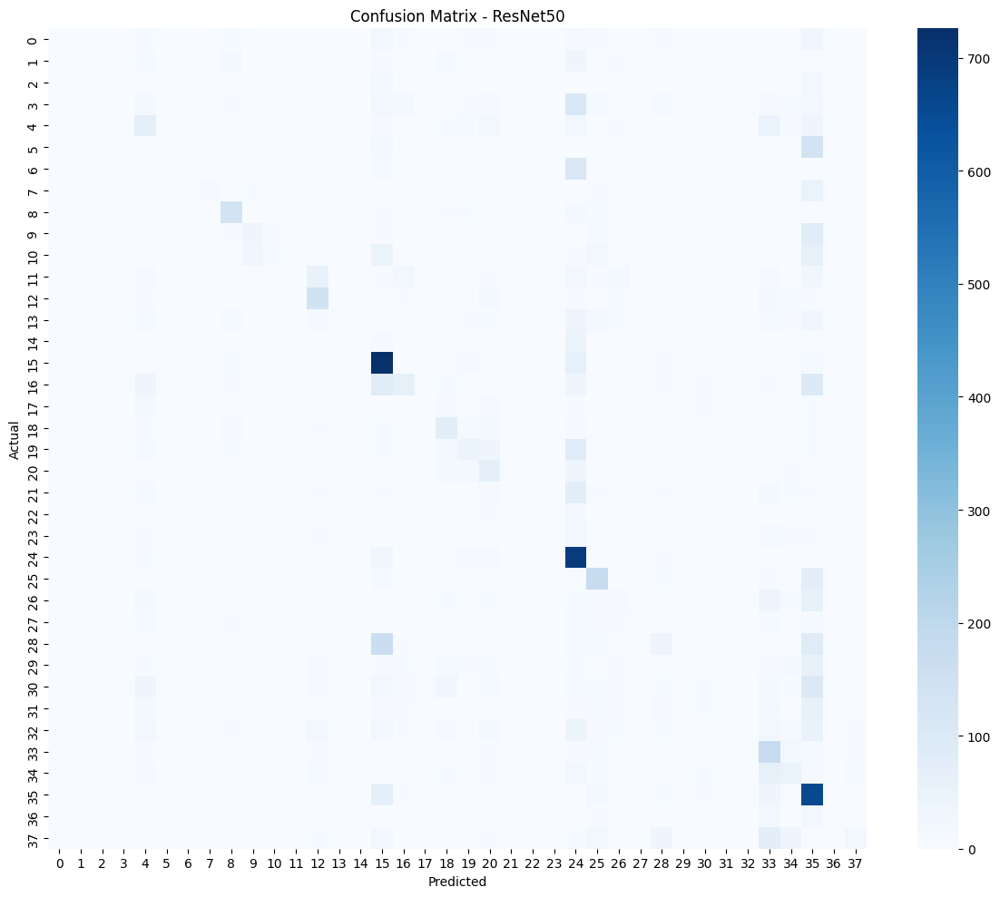


✅ Done!


In [13]:
print("Start")
# ============================================
# RESNET50 - PERFORMANCE METRICS ONLY
# ============================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
import os

# ============================================
# DEFINE YOUR PATHS
# ============================================
train_path = r"C:\Users\23301205\Downloads\archive\dataset_final\train"
test_path = r"C:\Users\23301205\Downloads\archive\dataset_final\test"

# Get class names
class_names = sorted(os.listdir(train_path))
num_classes = len(class_names)
print(f"Number of classes: {num_classes}")

# ============================================
# LOAD DATA FOR RESNET50
# ============================================
print("\nLoading data...")

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_path, image_size=(224,224), batch_size=32, label_mode='categorical'
).map(lambda x, y: (x/255.0, y)).prefetch(tf.data.AUTOTUNE)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_path, image_size=(224,224), batch_size=32, label_mode='categorical', shuffle=False
).map(lambda x, y: (x/255.0, y)).prefetch(tf.data.AUTOTUNE)

# ============================================
# BUILD RESNET50 MODEL
# ============================================
print("\nBuilding ResNet50 model...")

base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224,224,3))
base_model.trainable = False

model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model.compile(optimizer=Adam(learning_rate=0.001), 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# ============================================
# TRAIN RESNET50
# ============================================
print("\nTraining ResNet50...")
model.fit(train_ds, validation_data=test_ds, epochs=10, verbose=1)

# ============================================
# EVALUATE AND GET METRICS
# ============================================
print("\nEvaluating ResNet50...")

# Get predictions
y_pred = np.argmax(model.predict(test_ds), axis=1)

# Get true labels
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

# ============================================
# DISPLAY RESULTS
# ============================================
print("\n" + "="*50)
print("RESNET50 PERFORMANCE METRICS")
print("="*50)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("="*50)

# ============================================
# CONFUSION MATRIX
# ============================================
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - ResNet50')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

print("\n✅ Done!")

🏆 Best Model: ResNet50
📈 Best Accuracy: 0.9822 (98.22%)

All Model Accuracies:
  Random Forest: 0.6682 (66.82%)
  AdaBoost: 0.2411 (24.11%)
  KNN: 0.6752 (67.52%)
  CNN: 0.8145 (81.45%)
  ResNet50: 0.9822 (98.22%)


C:\Users\23301205\AppData\Local\Temp\ipykernel_6648\2512341717.py:70: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


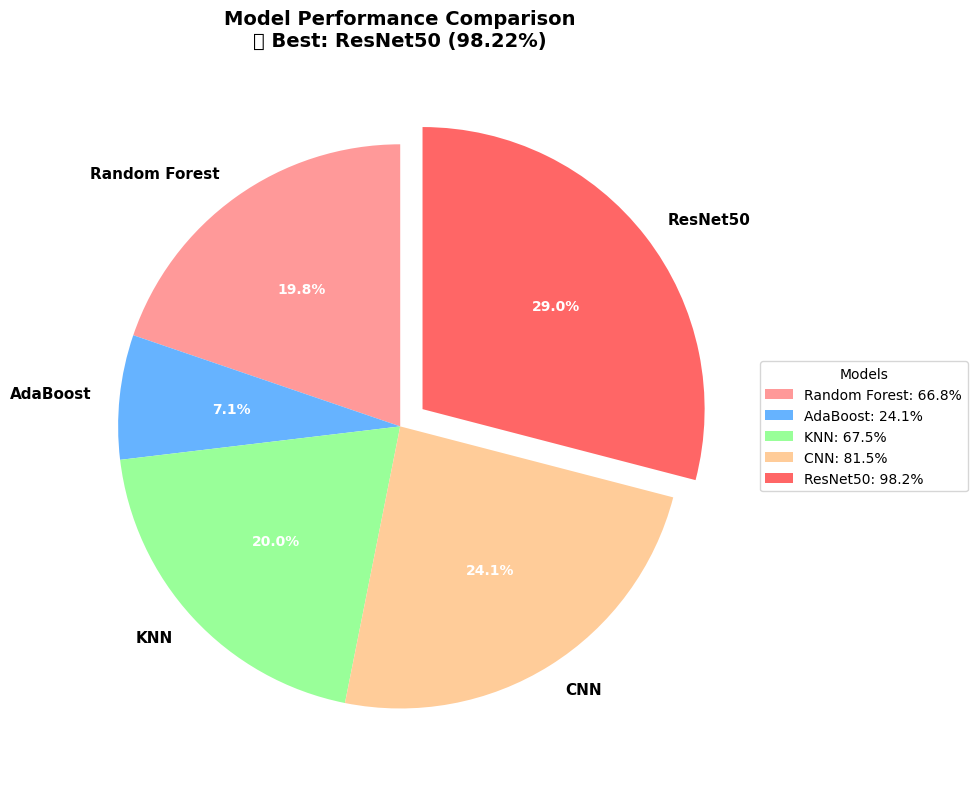

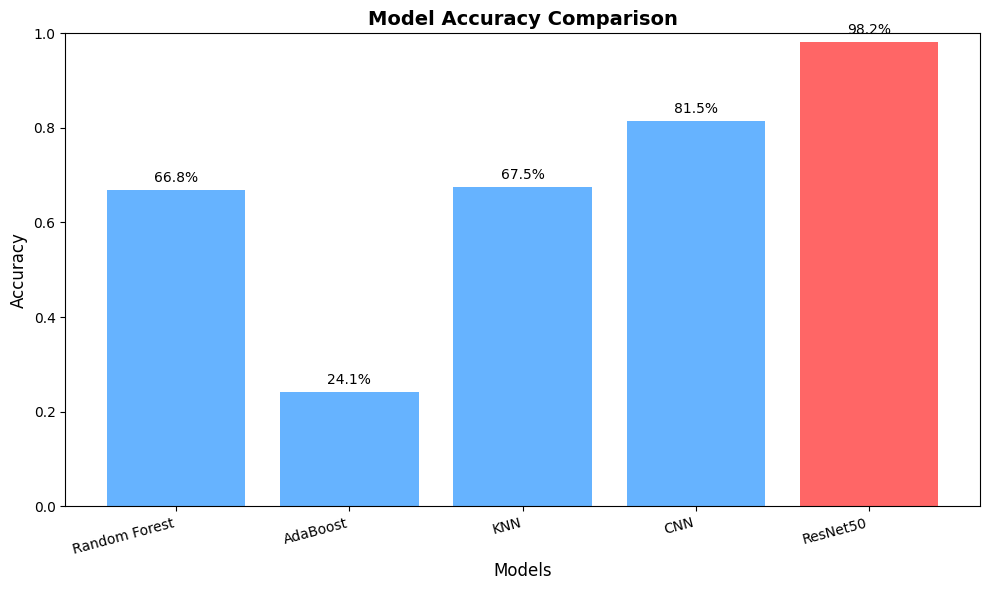


✅ Done!


In [16]:
# ============================================
# PIE CHART - BEST MODEL COMPARISON
# Based on your previous results
# ============================================

import matplotlib.pyplot as plt
import numpy as np

# ============================================
# ENTER YOUR RESULTS FROM PREVIOUS CODE
# (Replace these with your actual results)
# ============================================

results = {
    'Random Forest': 0.6682,  # Replace with your actual accuracy
    'AdaBoost': 0.2411,       # Replace with your actual accuracy
    'KNN': 0.6752,            # Replace with your actual accuracy
    'CNN': 0.8145,            # Replace with your actual accuracy
    'ResNet50': 0.9822        # Replace with your actual accuracy
}

# ============================================
# FIND BEST MODEL
# ============================================
best_model = max(results, key=results.get)
best_accuracy = results[best_model]

print(f"🏆 Best Model: {best_model}")
print(f"📈 Best Accuracy: {best_accuracy:.4f} ({best_accuracy*100:.2f}%)")
print("\nAll Model Accuracies:")
for model, acc in results.items():
    print(f"  {model}: {acc:.4f} ({acc*100:.2f}%)")

# ============================================
# CREATE PIE CHART
# ============================================
plt.figure(figsize=(10, 8))

# Colors for each model
colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#ff6666']

# Create pie chart
wedges, texts, autotexts = plt.pie(
    results.values(), 
    labels=results.keys(),
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    explode=[0.1 if model == best_model else 0 for model in results.keys()]  # Explode best model
)

# Style the text
for text in texts:
    text.set_fontsize(11)
    text.set_fontweight('bold')

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

# Add title
plt.title(f'Model Performance Comparison\n🏆 Best: {best_model} ({best_accuracy*100:.2f}%)', 
          fontsize=14, fontweight='bold', pad=20)

# Add legend
plt.legend(wedges, [f'{model}: {acc*100:.1f}%' for model, acc in results.items()],
          title="Models", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.show()

# ============================================
# BAR CHART FOR BETTER COMPARISON (OPTIONAL)
# ============================================
plt.figure(figsize=(10, 6))
models = list(results.keys())
accuracies = list(results.values())
colors_bar = ['#ff6666' if model == best_model else '#66b3ff' for model in models]

bars = plt.bar(models, accuracies, color=colors_bar)
plt.xlabel('Models', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Model Accuracy Comparison', fontsize=14, fontweight='bold')
plt.ylim(0, 1)

# Add value labels on bars
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{acc*100:.1f}%', ha='center', va='bottom', fontsize=10)

plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

print("\n✅ Done!")

In [31]:
# Classification Metrics for all models
print("start")
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, average='weighted'))
print("Recall:", recall_score(y_true, y_pred, average='weighted'))
print("F1-Score:", f1_score(y_true, y_pred, average='weighted'))

# Detailed per-class metrics
print("\nClassification Report:")
print(classification_report(y_true, y_pred))
print("done")

start
Accuracy: 0.3941435922567998
Precision: 0.2951032474050814
Recall: 0.3941435922567998
F1-Score: 0.2982034093973658

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        95
           1       0.00      0.00      0.00        94
           2       0.00      0.00      0.00        42
           3       0.00      0.00      0.00       247
           4       0.19      0.30      0.23       226
           5       0.00      0.00      0.00       158
           6       0.00      0.00      0.00       129
           7       0.85      0.14      0.24        77
           8       0.59      0.75      0.67       179
           9       0.49      0.24      0.32       148
          10       0.33      0.03      0.06       175
          11       0.50      0.01      0.01       177
          12       0.47      0.67      0.55       208
          13       0.00      0.00      0.00       162
          14       0.00      0.00      0.00 

C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\23301205\.conda\envs\gpu_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

In [58]:
# For Resnet model architecture
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.utils import plot_model

In [68]:
print("Start")
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    to_file='my_resnet_model.png',
    show_shapes=True,
    show_layer_names=True
)
print("Done")

Start
You must install pydot (`pip install pydot`) for `plot_model` to work.
Done
